# CLASIFICACIÓN

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.linear_model import SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

En estos ejemplos no vamos a seguir todo el proceso de un proyecto de machine learning para no extendernos demasiado, pero en un proyecto real hay que seguir todos los pasos.

## EJEMPLO 1: CLASIFICACIÓN BINARIA

Vamos a crear un clasificador binario que dentro del conjunto MNIST distinga entre 5 y no 5

### RECOPILACIÓN Y PREPARACIÓN  DE LOS DATOS

El conjunto de datos MNIST, es un conjunto de 70.000 imágenes pequeñas de dígitos escritos a mano por alumnos de instituto y empleados de la Oficina del Censo de EEUU. Cada imagen está etiquetada con el dígito al que representa.

Hay 70.000 imágenes y cada imagen tiene 784 características. Esto se debe a que cada imagen tiene 28 × 28 píxeles y cada característica representa simplemente la intensidad de un píxel, desde 0 (blanco) hasta 255 (negro). 

#### OBTENER LOS DATOS

In [3]:
mnist = fetch_openml('mnist_784', as_frame=False, parser="auto" )

#### EXPLORAR LOS DATOS

In [4]:
X, y = mnist.data, mnist.target
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(70000, 784))

In [5]:
X[0]

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,  18,  18,
       126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 17

In [6]:
X.shape

(70000, 784)

In [7]:
y

array(['5', '0', '4', ..., '4', '5', '6'], shape=(70000,), dtype=object)

In [7]:
y.shape

(70000,)

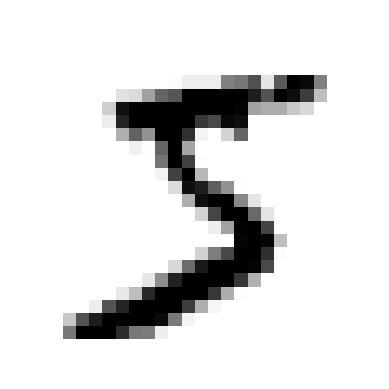

In [12]:
def plot_digit(image_data):
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")

some_digit = X[0]
plot_digit(some_digit)
plt.show()

In [9]:
y[0]

'5'

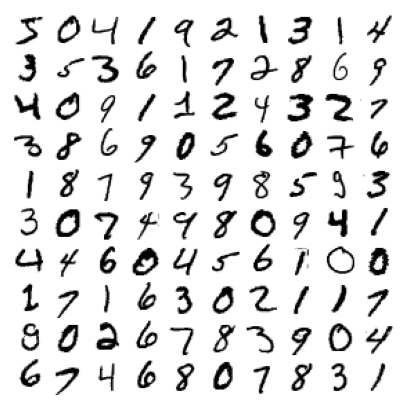

In [11]:
plt.figure(figsize=(5,5))
for idx, image_data in enumerate(X[:100]):
    plt.subplot(10, 10, idx + 1)
    plot_digit(image_data)
plt.subplots_adjust(wspace=0, hspace=0)
plt.show()

#### DIVIDIR LOS DATOS

En realidad, el conjunto de datos MNIST que devuelve fetch_openml() ya está dividido en un conjunto de entrenamiento (las primeras 60.000 imágenes) y un conjunto de prueba (las últimas 10.000)

In [8]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

#### PREPARAR LOS DATOS

In [9]:
y_train_5 = (y_train == '5')  # True para todos los 5s, False para el resto de dígitos
y_test_5 = (y_test == '5')

### ENTRENAMIENTO Y EVALUACIÓN DEL MODELO

Vamos a probar primero con un clasificador de descenso de gradientes estocástico.

In [14]:
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)

,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only i

Ya podemos usar el modelo para que prediga si la imagen es un 5 o no

In [15]:
sgd_clf.predict([some_digit])

array([ True])

#### VALIDACIÓN CRUZADA

In [16]:
cross_val_score(sgd_clf, X_train, y_train_5, cv=3, scoring="accuracy")

array([0.95035, 0.96035, 0.9604 ])

Los resultados so bastantes buenos pero hay que tener en cuenta que la accuracy no es la mejor medida para evaluar un clasificador binario puesto que si esta desequilibrado (hay muchos mas no 5 que 5) o el azar puede llevar a resultados que no sean tan buenos como pensamos.

Vamos a ver otras medidas para la evaluación de nuestro modelo.

#### MATRIZ DE CONFUSIÓN

Para calcular la matriz de confusión, primero hay que tener un conjunto de predicciones para poder compararlas con los objetivos reales. Podemos utilizar la función cross_val_predict().

Vamos a usar X_train e y_train, es decir, de momento sólo estamos evaluando en el conjunto de entrenamiento.

In [17]:
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3)

In [18]:
cm = confusion_matrix(y_train_5, y_train_pred)
cm

array([[53892,   687],
       [ 1891,  3530]])

|                   | No 5 (clase predicha) | 5 (clase predicha) |
|-------------------|-----------------------|--------------------|
| No 5 (clase real)	|                 53892	|                687 |
| 5 (clase real)	|                  1891	|               3530 |


#### PRECISIÓN  Y SENSIBILIDAD

Podemos fijarnos es la exactitud de las predicciones positivas, es decir, en la precisición del clasificador.

In [19]:
precision_score(y_train_5, y_train_pred)  #precision == 3530 / (687 + 3530)

0.8370879772350012

También podemos fijarnos en la tadas de verdaderos positivos, es decir, en la sensibilidad

In [20]:
recall_score(y_train_5, y_train_pred)  #sensibilidad == 3530 / (1891 + 3530)

0.6511713705958311

Cuando afirma que una imagen representa un 5, solo está en lo cierto el 83,7% de las veces. Además, solo detecta el 65,1% de los cincos. A menudo, es conveniente combinar precisión y sensibilidad en una sola métrica llamada valor F1, sobre todo cuando necesitas una sola métrica para comparar dos clasificadores.

In [21]:
f1_score(y_train_5, y_train_pred)

0.7325171197343847

#### CURVA DE ROC Y AUC (ÁREA BAJO LA CURVA DE ROC)

La función cross_val_predict realiza predicciones utilizando la técnica de validación cruzada (cross-validation) para cada punto de datos del conjunto de entrenamiento y si le añadimos el parametro method="decision_function" obtiene una puntuación en lugar de etiquetas de clase finales. Estas puntuaciones representan la confianza o probabilidad de que una instancia pertenezca a una clase específica, y pueden usarse para calcular métricas más avanzadas como la Curva ROC.

In [22]:
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3, method="decision_function")

In [23]:
fpr, tpr, _ = roc_curve(y_train_5, y_train_pred)

In [24]:
roc_auc = auc(fpr, tpr)
roc_auc

0.9604938554008616

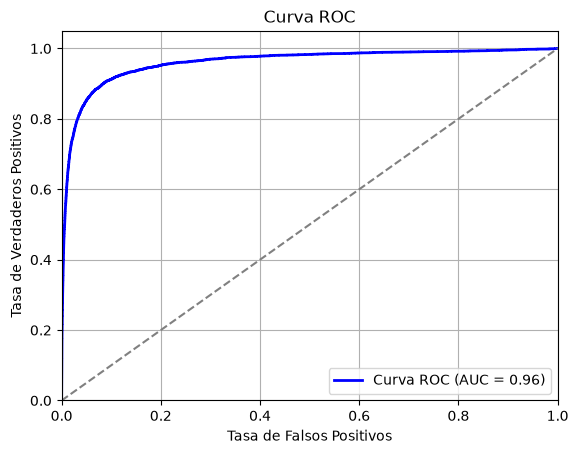

In [25]:
plt.figure()
plt.plot(fpr, tpr, color="blue", lw=2, label=f"Curva ROC (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")
plt.title("Curva ROC")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

Vamos a hacer los mismo pero vamos a usar ahora Random Forest

In [26]:
forest_clf = RandomForestClassifier(random_state=42)

In [27]:
y_train_forest_pred = cross_val_predict(forest_clf, X_train, y_train_5, cv=3)

In [28]:
cm = confusion_matrix(y_train_5, y_train_forest_pred)
cm

array([[54534,    45],
       [  725,  4696]])

In [29]:
precision_score(y_train_5, y_train_forest_pred)

0.9905083315756169

In [30]:
recall_score(y_train_5, y_train_forest_pred)

0.8662608374838591

In [31]:
f1_score(y_train_5, y_train_forest_pred)

0.9242275142688448

In [37]:
y_train_forest_pred = cross_val_predict(
    forest_clf, X_train, y_train_5, cv=3, method="predict_proba"
)

In [39]:
y_scores_forest = y_train_forest_pred[:, 1]
fpr, tpr, _ = roc_curve(y_train_5, y_scores_forest)

In [40]:
roc_auc = auc(fpr, tpr)
roc_auc

0.9983436731328145

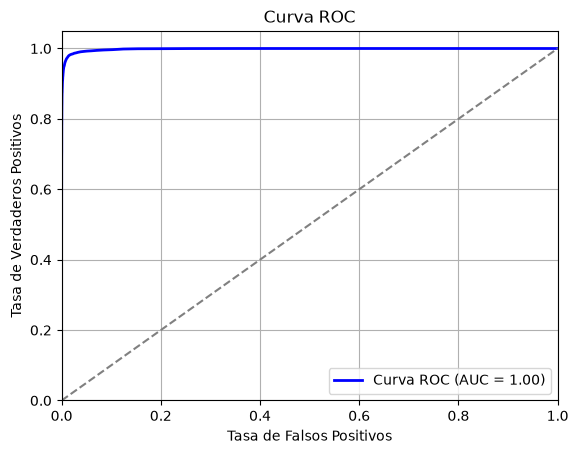

In [41]:
plt.figure()
plt.plot(fpr, tpr, color="blue", lw=2, label=f"Curva ROC (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")
plt.title("Curva ROC")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

Claramente este modelo es mejor y deberíamos pasar a la fase de optimización.

## EJEMPLO 2: CLASIFICADOR MULTICLASE

Vamos a crear un clasificador multiclase que dentro del conjunto MNIST nos diga que número del 0 al 9 es.

En este caso vamos a trabajar con y_train y y_test (en vez de y_train_5 y y_test_5).

Vamos a usar el modelo másquina de vectores de soporte (SVC)

### ENTRENAMIENTO Y EVALUACIÓN

In [10]:
svm_clf = SVC(random_state=42)
svm_clf.fit(X_train, y_train)  
#Si queremos que tarde menos
#svm_clf.fit(X_train[:2000], y_train[:2000])

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [13]:
svm_clf.predict([some_digit])

array(['5'], dtype=object)

Si llamamos al método decision_function(), veremos que devuelve 10 puntuaciones por instancia: una por clase. Cada clase obtiene una puntuación igual al número de duelos ganados más o menos un pequeño ajuste (máx. ± 0,33) para deshacer empates basándose en los resultados del clasificador: 

In [14]:
some_digit_scores = svm_clf.decision_function([some_digit])
some_digit_scores.round(2)

array([[ 1.73,  2.73,  7.25,  8.31, -0.31,  9.31,  1.71,  2.77,  6.23,
         4.85]])

La puntuación más alta es 9,3 y es, de hecho, la que se corresponde con la clase 5.

In [15]:
svm_clf.classes_

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype=object)

In [16]:
class_id = some_digit_scores.argmax()
svm_clf.classes_[class_id]

'5'

#### EXACTITUD

Podemos usar la función cross_val_score() con el scoring="accuracy" para evaluar el modelo con la métrica de exactitud: 

In [17]:
cross_val_score(svm_clf, X_train, y_train, cv=3, scoring="accuracy")

array([0.977 , 0.9738, 0.9739])

#### MATRIZ DE CONFUSIÓN

Vamos a fijarnos en la matriz de confusión.

Para esto, primero necesitamos hacer predicciones usando la función cross_val_predict(); después, podemos pasar las etiquetas y predicciones a la función confusion_matrix(), igual que hemos hecho antes. Sin embargo, como ahora hay 10 clases en vez de 2, la matriz de confusión contendrá muchos números y puede ser difícil de leer. Un diagrama de colores de la matriz de confusión, normalizarla y utilizar porcentajes en vez de números hace que la matriz sea mucho más fácil de analizar.

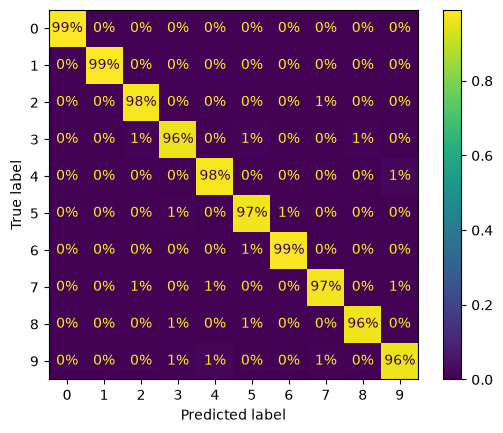

In [18]:
y_train_pred = cross_val_predict(svm_clf, X_train, y_train, cv=3)
ConfusionMatrixDisplay.from_predictions(
    y_train, y_train_pred, normalize="true", values_format=".0%"
)
plt.show()

Analizar la matriz de confusión a menudo da una perspectiva sobre las maneras de mejorar el clasificador. Si nos fijamos en estos gráficos, parece que deberíamos centrar nuestros esfuerzos en reducir los falsos ochos. Por ejemplo, podemos intentar reunir más datos de entrenamiento de dígitos que parezcan ochos (sin serlo) para que el clasificador aprenda a distinguirlos de los ochos de verdad. También podríamos preprocesar las imágenes para hacer que algunos patrones, como los círculos cerrados, destaquen más. 

## EJEMPLO 3

Vamos a echar un vistazo a un ejemplo sencillo, con fines ilustrativos.

Vamos a seguir utilizando el conjunto de datos MNIST, pero ahora queremos un clasificador que identifique dos caracteriscas: si un número es grande (7, 8 y 9) y si es impar.

### RECOPILACIÓN Y PREPARACIÓN DE LOS DATOS

#### PREPARAR LOS DATOS

El siguiente código crea una matriz y_labels que contiene dos etiquetas objetivo para cada imagen de dígito; la primera indica si el dígito es o no es grande (7, 8 o 9) y la segunda indica si es o no es impar. 

In [19]:
y_train_large = (y_train >= '7')
y_train_odd = (y_train.astype('int8') % 2 == 1)
y_labels = np.c_[y_train_large, y_train_odd]

### ENTRENAMIENTO Y EVALUACIÓN DEL MODELO

In [20]:
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_labels)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier",list,"[array([False, True]), array([False, True])]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [21]:
knn_clf.predict([some_digit])

array([[False,  True]])

#### VALIDACIÓN CRUZADA

In [22]:
y_train_knn_pred = cross_val_predict(knn_clf, X_train, y_labels, cv=3)

#### PRECISIÓN Y SENSIBILIDAD

Hay muchas formas de evaluar un clasificador multietique o multisalida y, en realidad, seleccionar la métrica adecuada depende del proyecto. 

Una forma de evaluar el clasificador es medir el valor F1  para cada etiqueta individual (o cualquier otra métrica) y, después, calcular la puntuación media. 

In [23]:
f1_score(y_labels, y_train_knn_pred, average="macro")

0.9764102655606048